# Module 08, Part 4: Denoising diffusion

This notebook is the runnable companion to Part 4 of the Module 08 learning content. It checks, with code:

1. That the closed-form forward process, which jumps straight to any noise level, matches adding noise one step at a time.
2. That a network trained only to predict the noise can generate samples by running the reverse process, first on eight Gaussians and then on real digits.
3. What the number of sampling steps costs and buys, using the same trained network with fewer, larger steps.
4. Whether a diffusion model conditioned on a label produces the requested digit.

The noise schedule has $T = 100$ steps. Digits are rescaled from $[0, 1]$ to $[-1, 1]$ for diffusion, and rescaled back (and clipped) before scoring.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
import math
import numpy as np
import torch


def ring_of_gaussians(n, n_modes=8, radius=2.0, std=0.05, seed=0):
    """n points from a mixture of n_modes Gaussians evenly spaced on a circle. Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, n_modes, (n,), generator=g)
    ang = 2 * math.pi * k.float() / n_modes
    centers = radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)
    return centers + std * torch.randn(n, 2, generator=g), k


def mode_centers(n_modes=8, radius=2.0):
    ang = 2 * math.pi * torch.arange(n_modes).float() / n_modes
    return radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)


def mode_coverage(samples, n_modes=8, radius=2.0, std=0.05, tol=6.0):
    """Return (modes covered, share of samples within tol*std of a mode centre).
    A mode counts as covered if at least 1 percent of the samples land near it."""
    c = mode_centers(n_modes, radius)
    d = torch.cdist(samples, c)
    near = d.min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=n_modes)
    return int((counts >= 0.01 * len(samples)).sum()), float(ok.float().mean())


def grid_centers(side=5, spacing=1.0):
    r = (torch.arange(side).float() - (side - 1) / 2) * spacing
    return torch.stack(torch.meshgrid(r, r, indexing="ij"), -1).reshape(-1, 2)


def grid_of_gaussians(n, side=5, spacing=1.0, std=0.05, seed=0):
    """n points from a side-by-side grid of Gaussians (25 modes for side=5). Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    c = grid_centers(side, spacing)
    k = torch.randint(0, len(c), (n,), generator=g)
    return c[k] + std * torch.randn(n, 2, generator=g), k


def grid_coverage(samples, side=5, spacing=1.0, std=0.05, tol=6.0):
    """(modes covered, share of samples within tol*std of a mode centre); a mode counts if it holds at least 0.4 percent of the samples."""
    c = grid_centers(side, spacing)
    near = torch.cdist(samples, c).min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=len(c))
    return int((counts >= 0.2 / len(c) * len(samples)).sum()), float(ok.float().mean())

In [4]:
import math
import torch
import torch.nn as nn


class Schedule:
    """Linear beta schedule. alpha_bar[t] is the share of the original signal left at step t."""

    def __init__(self, T=100, beta_min=1e-4, beta_max=0.1):
        self.T = T
        self.betas = torch.linspace(beta_min, beta_max, T)
        self.alphas = 1 - self.betas
        self.alpha_bar = torch.cumprod(self.alphas, 0)


def q_sample(sched, x0, t, noise=None):
    """Jump straight to step t of the forward process: x_t = sqrt(alpha_bar) x0 + sqrt(1 - alpha_bar) eps."""
    noise = torch.randn_like(x0) if noise is None else noise
    ab = sched.alpha_bar[t][:, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise


class Denoiser(nn.Module):
    """Predicts the noise that was added, given the noisy input, the step, and an optional one-hot label."""

    def __init__(self, d_data=2, d_hidden=128, T=100, n_classes=0):
        super().__init__()
        self.T, self.n_classes = T, n_classes
        self.net = nn.Sequential(nn.Linear(d_data + 16 + n_classes, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_data))

    @staticmethod
    def time_features(t, T):
        freqs = torch.exp(torch.linspace(0, math.log(100.0), 8))
        a = (t.float()[:, None] / T) * freqs[None]
        return torch.cat([torch.sin(a), torch.cos(a)], 1)

    def forward(self, x, t, c=None):
        h = [x, self.time_features(t, self.T)] + ([] if c is None else [c])
        return self.net(torch.cat(h, 1))


def train_diffusion(model, sched, X, y_onehot=None, steps=3000, batch_size=128, lr=2e-3, seed=0):
    """Minimize the mean squared error between the true noise and the predicted noise at a random step."""
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch_size,))
        x0 = X[idx]
        t = torch.randint(0, sched.T, (batch_size,))
        xt, eps = q_sample(sched, x0, t)
        c = None if y_onehot is None else y_onehot[idx]
        loss = ((model(xt, t, c) - eps) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        losses.append(float(loss.detach()))
    return losses


@torch.no_grad()
def sample_ddpm(model, sched, n, d_data, seed=0, labels=None, return_path=False):
    """Ancestral sampling: start from pure noise and apply the learned reverse step T times."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d_data, generator=g)
    c = None if labels is None else torch.nn.functional.one_hot(labels, model.n_classes).float()
    path = [x.clone()]
    for t in reversed(range(sched.T)):
        tt = torch.full((n,), t)
        eps = model(x, tt, c)
        a, ab, b = sched.alphas[t], sched.alpha_bar[t], sched.betas[t]
        mean = (x - b / (1 - ab).sqrt() * eps) / a.sqrt()
        x = mean + (b.sqrt() * torch.randn(x.shape, generator=g) if t > 0 else 0)
        if return_path: path.append(x.clone())
    return (x, path) if return_path else x


@torch.no_grad()
def sample_ddim(model, sched, n, d_data, n_steps=10, seed=0, labels=None):
    """Deterministic sampler that skips steps: the same trained network, n_steps evaluations instead of T."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d_data, generator=g)
    c = None if labels is None else torch.nn.functional.one_hot(labels, model.n_classes).float()
    ts = torch.linspace(sched.T - 1, 0, n_steps).round().long()
    for i, t in enumerate(ts):
        ab = sched.alpha_bar[t]
        ab_next = sched.alpha_bar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        eps = model(x, torch.full((n,), int(t)), c)
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        x = ab_next.sqrt() * x0 + (1 - ab_next).sqrt() * eps
    return x

In [5]:
import numpy as np
import torch
import torch.nn as nn
from scipy import linalg


class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

## 1. The forward process in one jump

Each forward step shrinks the signal and adds a little noise: $x_t = \sqrt{1 - \beta_t}\,x_{t-1} + \sqrt{\beta_t}\,\epsilon$. Because the sum of independent Gaussians is Gaussian, the whole chain collapses to
$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon$ with $\bar\alpha_t = \prod_{s \le t}(1 - \beta_s)$. This is what makes training cheap: we never have to simulate the chain.
We check it on data that start at 1.5, comparing 100,000 chains run step by step with 100,000 draws from the closed form.

In [6]:
sched = Schedule(T=100)
torch.manual_seed(0)
x = torch.full((100000, 1), 1.5)
checkpoints = {10: None, 50: None, 99: None}
for t in range(100):
    x = sched.alphas[t].sqrt() * x + sched.betas[t].sqrt() * torch.randn_like(x)
    if t in checkpoints: checkpoints[t] = (x.mean().item(), x.std().item())
print("step   iterated mean, std      closed-form mean, std      alpha_bar")
for t, (m, s) in checkpoints.items():
    xt, _ = q_sample(sched, torch.full((100000, 1), 1.5), torch.full((100000,), t))
    print(f"{t:4d}   {m:8.4f}, {s:6.4f}         {xt.mean():8.4f}, {xt.std():6.4f}            {sched.alpha_bar[t]:.4f}")
print(f"\nshare of the original signal's amplitude left at the last step: {sched.alpha_bar[-1].sqrt():.4f}")

step   iterated mean, std      closed-form mean, std      alpha_bar
  10     1.4576, 0.2351           1.4569, 0.2362            0.9448
  50     0.7791, 0.8545           0.7747, 0.8519            0.2687
  99     0.1138, 1.0006           0.1104, 0.9992            0.0056

share of the original signal's amplitude left at the last step: 0.0750


The two columns agree, and at the last step almost nothing of the original survives, so the reverse process can start from pure noise. How much survives is a design choice: a schedule that leaves too much signal at the last step makes
the starting point of sampling (pure noise) differ from the distribution the network was trained to denoise.

## 2. Learning to remove noise: eight Gaussians

The network gets a noisy point, the step number and nothing else, and predicts the noise that was added. Training minimizes the squared error between the true and predicted noise at a random step. Sampling starts
from noise and applies the learned reverse step 100 times.

In [7]:
Xr, _ = ring_of_gaussians(5000)
torch.manual_seed(0)
model_r = Denoiser(d_data=2, d_hidden=128, T=100)
t0 = time.time()
losses = train_diffusion(model_r, sched, Xr, steps=4000, lr=2e-3, seed=0)
print(f"trained in {time.time() - t0:.0f} s, final noise-prediction loss {np.mean(losses[-200:]):.3f}")
out, path = sample_ddpm(model_r, sched, 2000, 2, seed=9, return_path=True)
print("modes covered and share near a mode:", mode_coverage(out))

trained in 6 s, final noise-prediction loss 0.296
modes covered and share near a mode: (8, 0.902999997138977)


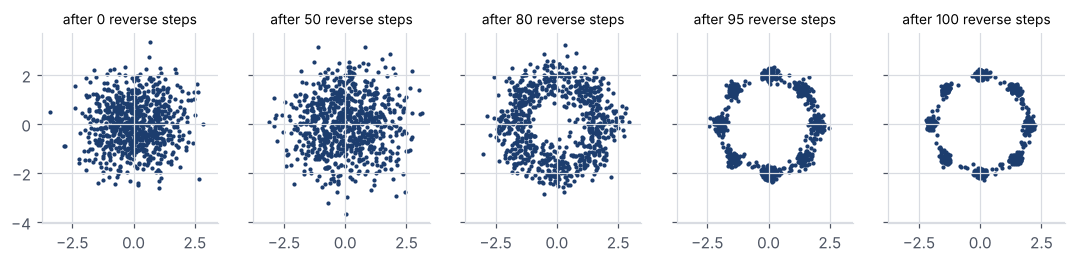

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8), sharex=True, sharey=True)
for ax, k in zip(axes, [0, 50, 80, 95, 100]):
    ax.scatter(path[k][:800, 0], path[k][:800, 1], s=3, color=NAVY); ax.set_aspect("equal")
    ax.set_title(f"after {k} reverse steps", fontsize=9)
plt.show()

The panels show the reverse process: a blob of noise that gradually organizes into eight tight clusters. Most of the structure appears in the last twenty steps. Compare this with a GAN, which makes the whole sample in one pass of the generator.

## 3. Diffusion on real digits

The same recipe, with a wider network (256 hidden units) and 64-dimensional inputs, three seeds. We score 359 generated images exactly as in Parts 2 and 3: Fréchet distance to the test set, precision, recall, and the nearest-training-image distance.

In [9]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
fte = get_features(net, Xte)
def score(s):
    f = get_features(net, s)
    p, r = precision_recall(fte, f)
    return frechet_distance(f, fte), p, r, nearest_train_distance(s, Xtr).mean().item()

dig = []
for seed in range(3):
    m = Denoiser(d_data=64, d_hidden=256, T=100)
    t0 = time.time()
    train_diffusion(m, sched, Xtr * 2 - 1, steps=4000, lr=1e-3, seed=seed)
    tt = time.time() - t0
    t0 = time.time()
    s = ((sample_ddpm(m, sched, 359, 64, seed=9) + 1) / 2).clamp(0, 1)
    st = time.time() - t0
    fd, p, r, nn_d = score(s)
    dig.append(dict(model=m, samples=s, fd=fd, p=p, r=r, nn=nn_d, train_s=tt, sample_s=st))
    print(f"seed {seed}: Frechet {fd:5.1f}  precision {p:.2f}  recall {r:.2f}  nearest training image {nn_d:.2f}  (train {tt:.0f} s, sample {st:.1f} s)", flush=True)
print(f"mean over seeds: Frechet {np.mean([d['fd'] for d in dig]):.1f}, precision {np.mean([d['p'] for d in dig]):.2f}, recall {np.mean([d['r'] for d in dig]):.2f}")

seed 0: Frechet  10.6  precision 0.78  recall 0.82  nearest training image 1.48  (train 9 s, sample 0.1 s)


seed 1: Frechet  11.2  precision 0.77  recall 0.83  nearest training image 1.48  (train 9 s, sample 0.1 s)


seed 2: Frechet  11.6  precision 0.75  recall 0.84  nearest training image 1.50  (train 9 s, sample 0.1 s)


mean over seeds: Frechet 11.1, precision 0.77, recall 0.83


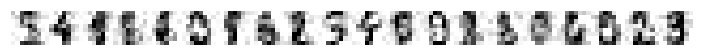

In [10]:
fig, ax = plt.subplots(figsize=(8, 1.6))
ax.imshow(np.concatenate(list(dig[0]["samples"][:20].reshape(-1, 8, 8)), 1), cmap="gray_r"); ax.axis("off")
plt.show()

## 4. How many steps do you need?

The network is trained for all 100 noise levels. At sampling time we can skip steps with a deterministic sampler (DDIM): the same trained network is evaluated at fewer noise levels, each time jumping further.
Cost is the number of network evaluations per sample, so it is the lever that decides whether diffusion is practical. We score seed 0's network with 5, 10, 25, 50 and 100 evaluations (100 uses the full ancestral sampler).

In [11]:
m0 = dig[0]["model"]
print("evaluations   Frechet   precision   recall   seconds for 359 samples")
step_rows = []
for k in [5, 10, 25, 50, 100]:
    t0 = time.time()
    raw = sample_ddpm(m0, sched, 359, 64, seed=9) if k == 100 else sample_ddim(m0, sched, 359, 64, n_steps=k, seed=9)
    sec = time.time() - t0
    s = ((raw + 1) / 2).clamp(0, 1)
    fd, p, r, _ = score(s)
    step_rows.append((k, fd, p, r, sec))
    print(f"{k:11d}   {fd:7.1f}   {p:9.2f}   {r:6.2f}   {sec:6.2f}")

evaluations   Frechet   precision   recall   seconds for 359 samples
          5       9.7        0.75     0.93     0.01
         10       8.0        0.77     0.94     0.01
         25       8.5        0.77     0.95     0.03


         50       8.7        0.77     0.94     0.04
        100      10.6        0.78     0.82     0.09


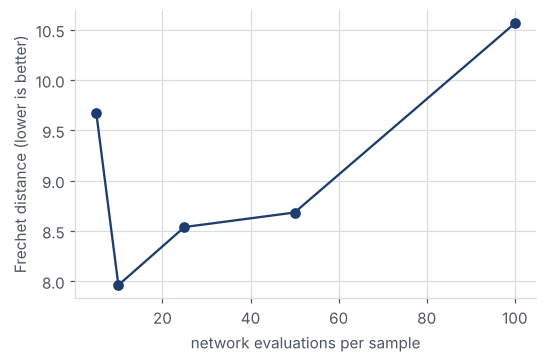

In [12]:
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.plot([r[0] for r in step_rows], [r[1] for r in step_rows], "o-", color=NAVY)
ax.set_xlabel("network evaluations per sample"); ax.set_ylabel("Frechet distance (lower is better)")
plt.show()

Quality improves as the number of evaluations grows, with most of the gain in the first few dozen. Fewer steps trade quality for speed, and that is the central practical cost of diffusion models against a GAN, which needs one evaluation per sample.

## 5. Conditioning on a label

To ask for a particular digit we give the denoiser the one-hot label as an extra input, both in training and in sampling. We generate 100 images per digit and let the feature network's classifier decide which digit each one is.

In [13]:
mc = Denoiser(d_data=64, d_hidden=256, T=100, n_classes=10)
train_diffusion(mc, sched, Xtr * 2 - 1, y_onehot=one_hot(ytr), steps=4000, lr=1e-3, seed=0)
shares = []
for d in range(10):
    labels = torch.full((100,), d)
    s = ((sample_ddpm(mc, sched, 100, 64, seed=d, labels=labels) + 1) / 2).clamp(0, 1)
    shares.append((net(s).argmax(1) == d).float().mean().item())
print("share of samples classified as the requested digit, per digit:")
print(" ".join(f"{d}: {s:.2f}" for d, s in enumerate(shares)))
print(f"mean {np.mean(shares):.3f}")

share of samples classified as the requested digit, per digit:
0: 1.00 1: 0.85 2: 0.98 3: 0.96 4: 0.99 5: 0.97 6: 1.00 7: 0.98 8: 0.90 9: 0.91
mean 0.954


A label given to the network at every step steers the reverse process towards that class. Checking with a classifier is how you verify that conditioning works, since "it looks right" is not a measurement.